# 08 · Front tracking on the circle $S^1$

The setup follows `fronttrack.periodic` (scalar-front-tracking). Items live in cyclic order on
the chart $[n_0, n_0+L)$, and the seam is a node of $g_\Delta$, so a front
crosses it through an ordinary corner event. A **well-signed** $g$ gives
genuine wraparound and exact conservation of mass. Zeros split the circle
into independent sign arcs, one of which may cross the seam.

In [1]:
# Use the local checkout if present; otherwise install from GitHub (needs the repository to be public).
import sys, subprocess, importlib.util
from pathlib import Path
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/hetfront/__init__.py").is_file()), None)
if local_src is not None:
    sys.path.insert(0, str(local_src))
elif importlib.util.find_spec("hetfront") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/parasuramv/heterogeneous-front-tracking"])
import numpy as np
import matplotlib.pyplot as plt
import hetfront
from hetfront import (HeteroFrontTracker, PeriodicHeteroFrontTracker, MultiplicativeFlux,
                      PiecewiseAffine, trajectory)
from hetfront.visualization import (observe_tracker, plot_spacetime, plot_profile,
                                    plot_heterogeneity, plot_diagnostics, plot_circle, overview)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
print("hetfront", hetfront.__version__, "from", "local checkout" if local_src else "installed package")

hetfront 0.1.0 from local checkout


## Well-signed: wraparound and exact mass

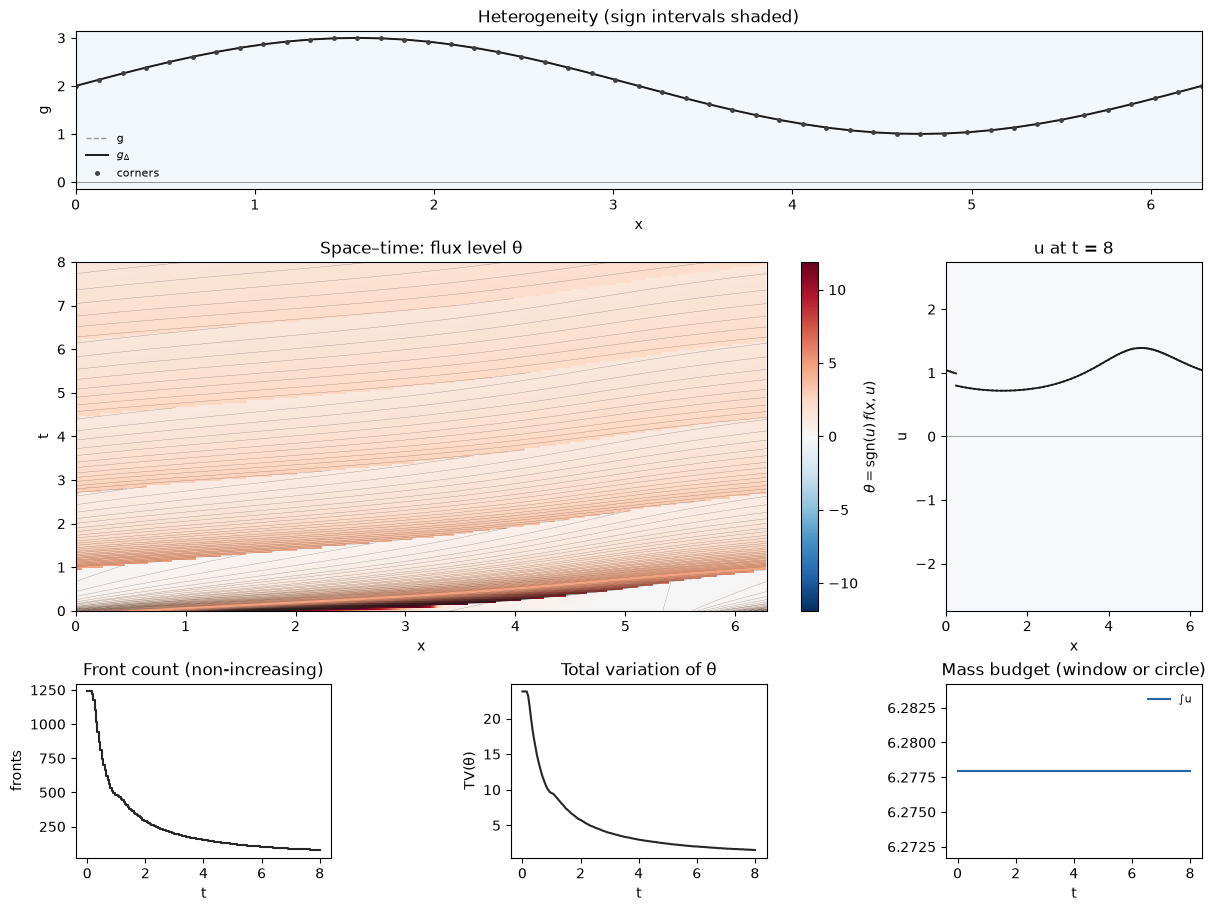

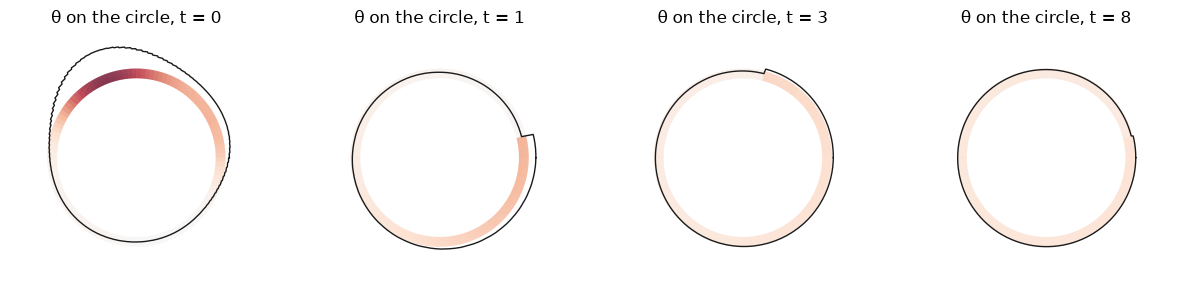

mass drift over the run: 2.6645352591003757e-15
seam crossings are corner events: 68547 corners in total


In [2]:
L = 2 * np.pi
g_exact = lambda x: 2 + np.sin(x)
g = PiecewiseAffine.from_function(g_exact, np.linspace(0, L, 48, endpoint=False), period=L)
flux = MultiplicativeFlux(g, 0.01)
tr = PeriodicHeteroFrontTracker.from_function(flux, lambda x: 1 + 0.8 * np.sin(x) + 0.3 * np.cos(3 * x), cells=120)
h = observe_tracker(tr, np.linspace(0, L, 801, endpoint=False), np.linspace(0, 8, 161))
overview(h, exact_g=g_exact)
plt.show()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, t in zip(axes, (0, 1, 3, 8)):
    plot_circle(h, int(np.searchsorted(h.times, t)), ax=ax)
plt.show()
print("mass drift over the run:", h.diagnostics["mass"][-1] - h.diagnostics["mass"][0])
print("seam crossings are corner events:", tr.counts["corner"], "corners in total")

## Homogenisation: derive the coefficient before measuring the error

Assume $g$ is periodic and **bounded away from zero**, with constant sign
$\eta\in\{-1,1\}$. Let $m=\langle |g|^{-1/2}\rangle$, where brackets
denote the **normalised** average over one microscopic period. A stationary
level has mean $p=\eta s(\theta)m$ and flux $\eta|\theta|$. Eliminating
$\theta$ gives

$$\bar F(p)=c p^2,\qquad c=\eta m^{-2},\qquad
  \theta=\eta p|p|/m^2,\qquad
  U[\theta](x)=\rho(x)p,\quad \rho=|g|^{-1/2}/m.$$

The sign matters: negative $g$ gives a **concave** effective flux. Below
$g>0$. Since this experiment uses $u^2$, rather than $u^2/2$, we have
$\bar F''=2/m^2$. For positive $g$, the draft's formula
$(\langle F_{uu}^{-1/2}\rangle)^{-2}$ gives the same value because
$F_{uu}=2g$. No such formula is being asserted across zeros of $g$.

### Exact spatial change of variables

Define $z(x)=\int_0^x\rho(\xi)\,d\xi$ and $u(x,t)=\rho(x)v(z(x),t)$.
Since $g\rho^2=c$ and $z'=\rho>0$,

$$u_t+(gu^2)_x=\rho\,[v_t+(cv^2)_z].$$

This also transfers weak formulations and Rankine–Hugoniot speeds. It
works across nonzero corners, where $\rho$ is continuous, and preserves
the shock/rarefaction rule. Map the initial jumps by $z$ and retain their
integer levels to obtain an **exact conjugacy of the two front trackers**.
Tests exercise this identity for signed data and both signs of $g$.
Homogenisation compares instead with macroscopic initial jumps left at
their original positions. Because $\langle\rho\rangle=1$, $z(x)-x$ is
periodic and $O(\varepsilon)$.

`PeriodicStraightening` integrates the **actual piecewise-affine** $g_\Delta$
exactly. Its coefficient $c_\Delta$ differs from that of the smooth sine.
Keeping a fixed number of nodes per period fixes the microscopic shape
error; reducing ε alone does not remove that error.

### A corrector bound, not merely a fitted slope

Put $d=\|z-\mathrm{id}\|_\infty=O(\varepsilon)$. The inverse map has
the same displacement bound. For a periodic BV function $q$ and an
increasing map $\psi$ with $|\psi-\mathrm{id}|\le d$, integration against
$|Dq|$ gives $\|q\circ\psi-q\|_1\le2d\mathrm{TV}(q)$.
The transformed initial datum is $p_0\circ z^{-1}$. Homogeneous $L^1$
contraction, followed by this displacement estimate and TVD, yields

$$\|u^\varepsilon(t)-\rho\bar u(t)\|_{L^1(dx)}
=\|v(t)-\bar u(t)\circ z^{-1}\|_{L^1(dz)}
\le4d\mathrm{TV}(p_0).$$

The first term compares $v$ with $\bar u$ using their initial data; the
second compares $\bar u$ with $\bar u\circ z^{-1}$. Each costs at most
$2d\mathrm{TV}(p_0)$. The same argument works at fixed δ for the
homogeneous polygonal flux on the level-state grid. Thus the dynamic
experiment below can check this bound for its quantised prepared data,
while still keeping continuum discretisation error separate.

In [3]:
from hetfront.homogenisation import PeriodicStraightening
from hetfront.studies import fitted_order

def oscillating_coefficient(n_periods, nodes_per_period):
    # Integer period counts ensure that g fits the unit circle exactly.
    nodes = np.arange(nodes_per_period * n_periods) / (nodes_per_period * n_periods)
    g = PiecewiseAffine(nodes, 2 + np.sin(2 * np.pi * n_periods * nodes), period=1.0)
    return g, PeriodicStraightening(g)

# Smooth coefficient: midpoint quadrature is used only for this separate
# resolution comparison, never in the exact interpolant coefficient.
y = (np.arange(100000) + 0.5) / 100000
c_smooth = np.mean((2 + np.sin(2 * np.pi * y)) ** -0.5) ** -2
print("nodes/period    c_Delta             |c_Delta-c_smooth|")
for nodes_per_period in (8, 16, 32, 64):
    _, mapping = oscillating_coefficient(1, nodes_per_period)
    print(f"{nodes_per_period:12}  {mapping.coefficient:.12f}   {abs(mapping.coefficient-c_smooth):.3e}")

nodes/period    c_Delta             |c_Delta-c_smooth|
           8  1.819187909193   2.109e-02
          16  1.803632392963   5.530e-03
          32  1.799501625184   1.399e-03
          64  1.798453267211   3.509e-04


### An exact obstruction to uncorrected strong convergence

For constant macroscopic state $p\ne0$, $u^\varepsilon=\rho(x/\varepsilon)p$
is stationary, and its mean is $p$. On the unit circle with an integer
number of periods,

$$\|u^\varepsilon-p\|_{L^1}=|p|\langle|\rho-1|\rangle>0$$

for nonconstant $g$. Yet its primitive difference is $O(\varepsilon)$.
Thus uncorrected strong convergence fails **in general**; it does not
fail for every datum (the zero datum is an immediate exception).
Strong convergence to the stationary corrector $\rho\bar u$ is a
different question. The following stationary check has no evolution error.

In [4]:
print("epsilon  primitive max (sampled)  uncorrected L1 (quadrature)  corrected L1 (exact)")
for n in (2, 4, 8, 16):
    g, mapping = oscillating_coefficient(n, 32)
    flux = MultiplicativeFlux(g, 0.01)
    stationary = PeriodicHeteroFrontTracker(flux, [], [100])
    effective = PeriodicHeteroFrontTracker(
        MultiplicativeFlux(PiecewiseAffine.constant(mapping.coefficient, period=1), 0.01), [], [100])
    x = np.linspace(0, 1, 256 * n + 1)
    primitive_error = np.max(np.abs(stationary.primitive(x) - effective.primitive(x)))
    p = effective.sample_u(0)
    # Sample one microscopic period at fixed high resolution to avoid aliasing.
    micro_x = (np.arange(10000) + 0.5) / (10000 * n)
    raw_l1 = abs(p) * np.mean(np.abs(mapping.density(micro_x) - 1))
    corrected = mapping.corrector_l1(stationary, effective)
    assert corrected < 1e-12
    print(f"{1/n:7.4f}  {primitive_error:24.6e}  {raw_l1:28.6e}  {corrected:20.2e}")

epsilon  primitive max (sampled)  uncorrected L1 (quadrature)  corrected L1 (exact)
 0.5000              3.181972e-02                  1.285442e-01              1.66e-16
 0.2500              1.590986e-02                  1.285442e-01              1.66e-16
 0.1250              7.954929e-03                  1.285442e-01              1.66e-16
 0.0625              3.977465e-03                  1.285442e-01              1.66e-16


### Dynamic prepared data: separate the measurements

We approximate $p_0(x)=0.6+0.5\sin(2\pi x)$ by midpoint samples and
quantise $\theta=c_\Delta p_0|p_0|$. The resulting data are exactly
$u_0=\rho p_{0,\delta}$ for a step function $p_{0,\delta}$.
Their microscopic-period average is not exactly $p_0$ when $p_0$ varies
inside that period. Both runs use the same quantised macroscopic data.

We measure (i) a **sampled maximum of the anchored primitive difference**,
(ii) exact $L^1$ error against $\rho\bar u_\delta$, and (iii) the initial
mass mismatch, which is conserved. The first is a potential diagnostic,
not a computed $W^{-1,1}$ norm or a period-average error. Each primitive
value is exact up to roundoff; its maximum over a grid is not a certified
continuum supremum. The comparison solution is itself a finite-δ front
approximation. A fitted slope is evidence about these runs, not a proof.

epsilon   sampled primitive max    exact corrector L1    initial mass gap


 0.5000            2.996214e-02         2.574212e-02   -4.802863e-06


 0.2500            1.849459e-02         1.361478e-02   -9.989699e-06


 0.1250            9.273145e-03         4.476690e-03   -7.306503e-06


 0.0625            4.571526e-03         2.536585e-03   -1.178713e-06
observed primitive slope: 0.9133151918842898
observed corrector slope: 1.1634183697085327


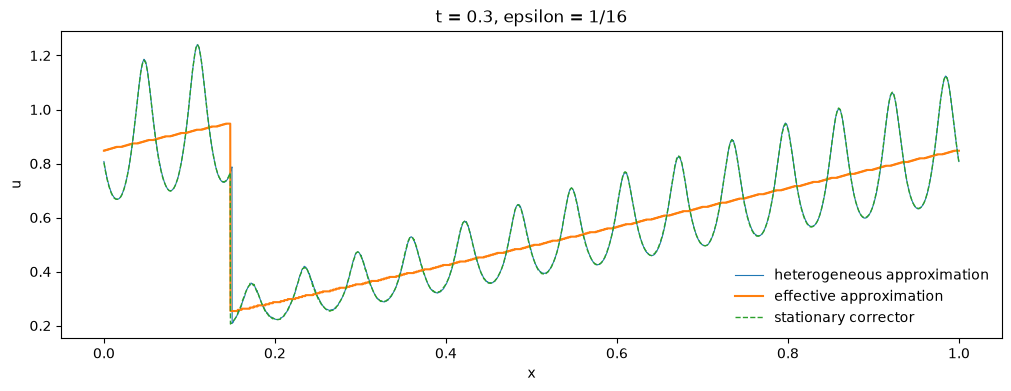

In [5]:
def prepared_comparison(n_periods, *, delta=0.004, data_cells=200,
                        nodes_per_period=32, T=0.3):
    g, mapping = oscillating_coefficient(n_periods, nodes_per_period)
    c = mapping.coefficient
    edges = np.arange(data_cells) / data_cells
    mids = edges + 0.5 / data_cells
    p0 = 0.6 + 0.5 * np.sin(2 * np.pi * mids)
    theta = c * p0 * np.abs(p0)
    het = PeriodicHeteroFrontTracker.from_theta(
        MultiplicativeFlux(g, delta), edges, theta, record_history=False)
    hom = PeriodicHeteroFrontTracker.from_theta(
        MultiplicativeFlux(PiecewiseAffine.constant(c, period=1), delta),
        edges, theta, record_history=False)
    initial_mass_gap = het.integral() - hom.integral()
    p_delta = hom.sample_u(mids)
    initial_tv = np.sum(np.abs(p_delta - np.roll(p_delta, 1)))
    het.run(T); hom.run(T)
    assert abs(het.integral() - hom.integral() - initial_mass_gap) < 2e-11
    # Maintain at least 128 observation points per microscopic period.
    x = np.linspace(0, 1, max(2048, 128 * n_periods) + 1)
    primitive_error = np.max(np.abs(het.primitive(x) - hom.primitive(x)))
    corrected = mapping.corrector_l1(het, hom)
    bound = 4 * mapping.displacement_bound() * initial_tv
    assert corrected <= bound + 2e-11
    return (primitive_error, corrected, initial_mass_gap), het, hom, mapping

results = []
print("epsilon   sampled primitive max    exact corrector L1    initial mass gap")
for n in (2, 4, 8, 16):
    metrics, het, hom, mapping = prepared_comparison(n)
    results.append((1/n, *metrics))
    print(f"{1/n:7.4f}   {metrics[0]:21.6e}   {metrics[1]:18.6e}   {metrics[2]:+.6e}")
print("observed primitive slope:", fitted_order([r[0] for r in results], [r[1] for r in results]))
print("observed corrector slope:", fitted_order([r[0] for r in results], [r[2] for r in results]))
x = np.linspace(0, 1, 4001)
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.plot(x, het.sample_u(x), lw=0.8, label="heterogeneous approximation")
ax.plot(x, hom.sample_u(x), lw=1.5, label="effective approximation")
ax.plot(x, mapping.density(x) * hom.sample_u(x), lw=1, ls="--", label="stationary corrector")
ax.set(xlabel="x", ylabel="u", title="t = 0.3, epsilon = 1/16")
ax.legend(frameon=False)
plt.show()

### Resolution sensitivity at fixed ε

Vary δ, data sampling, and coefficient resolution separately. Also double
the observation-grid density. Agreement here supports the measured values;
it does not establish a uniform numerical error bound as ε tends to zero.
In particular, fixed-resolution ε slopes cannot certify a continuum rate.

In [6]:
print("delta  data cells  nodes/period    primitive max    corrector L1")
for delta, data_cells, nodes_per_period in ((0.008,200,32), (0.004,200,32),
        (0.002,200,32), (0.004,100,32), (0.004,400,32),
        (0.004,200,16), (0.004,200,64)):
    metrics, _, _, _ = prepared_comparison(16, delta=delta, data_cells=data_cells,
                                           nodes_per_period=nodes_per_period)
    print(f"{delta:.3f}  {data_cells:10}  {nodes_per_period:12}    {metrics[0]:.6e}    {metrics[1]:.6e}")
for samples in (2049, 4097):
    x = np.linspace(0, 1, samples)
    print("primitive max at", samples, "points:", np.max(np.abs(het.primitive(x)-hom.primitive(x))))

delta  data cells  nodes/period    primitive max    corrector L1


0.008         200            32    4.571977e-03    2.492045e-03


0.004         200            32    4.571526e-03    2.536585e-03


0.002         200            32    4.570993e-03    2.539798e-03


0.004         100            32    4.588608e-03    2.712874e-03


0.004         400            32    4.581688e-03    2.585698e-03


0.004         200            16    4.515552e-03    2.698172e-03


0.004         200            64    4.587588e-03    2.511320e-03
primitive max at 2049 points: 0.004571525660989631
primitive max at 4097 points: 0.004571525660989895


## Sign arcs on the circle
$g = \sin 2\pi(x - 0.8)$ has zeros at 0.3 and 0.8, so the arc $(0.8, 1.3)$ crosses the seam. Both arcs evolve independently, absorbing fronts at their ends.

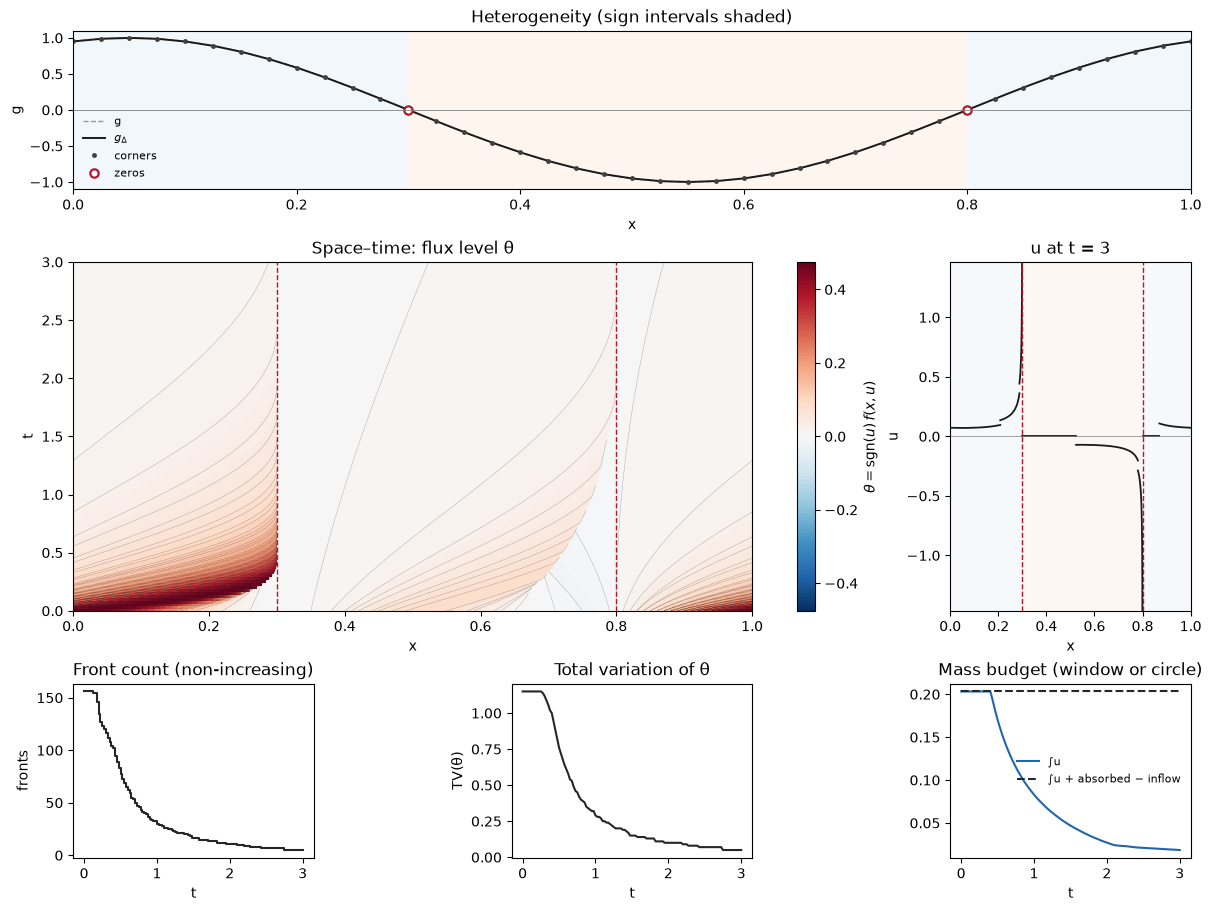

arcs: [(0.29999999999999993, 0.8, -1.0), (0.8, 1.2999999999999998, 1.0)]
budget residual: 6.317724121629453e-13
interface condition holds: True | events: {'collision': 71, 'corner': 1802, 'absorption': 80, 'initial_emission': 2}


In [7]:
g_exact = lambda x: np.sin(2 * np.pi * (x - 0.8))
g = PiecewiseAffine.from_function(g_exact, np.linspace(0, 1, 40, endpoint=False), period=1.0)
flux = MultiplicativeFlux(g, 0.005)
tr = PeriodicHeteroFrontTracker.from_function(flux, lambda x: 0.5 * np.cos(2 * np.pi * x) + 0.2, cells=100)
h = observe_tracker(tr, np.linspace(0, 1, 801, endpoint=False), np.linspace(0, 3, 121))
overview(h, exact_g=g_exact)
plt.show()
d = h.diagnostics
print("arcs:", g.sign_intervals())
print("budget residual:", np.max(np.abs(d["mass"] + d["absorbed"] - d["mass"][0])))
print("interface condition holds:", tr.interface_admissible(), "| events:", {k: v for k, v in tr.counts.items() if v})

## Agreement with `fronttrack.periodic`
For constant $g$ the circle tracker coincides with `fronttrack.PeriodicFrontTracker` on the state grid $U[\delta\mathbb Z]$; see `tests/test_periodic.py::CircleOracleTests`.